In [30]:
# Import warning 
import warnings 
warnings.filterwarnings('ignore') 

# Model import 
from dotenv import load_dotenv 
import os 
load_dotenv()

from langchain_core.messages import HumanMessage , SystemMessage

key = os.getenv("GROQ_API_KEY")
from langchain_groq import ChatGroq 
LLM = ChatGroq(model="openai/gpt-oss-120b",temperature=0.7)

# Give Rocket its own personal identity 
system_prompt = """
You are Rocket, a personal AI voice assistant.

Rules:
- Reply in simple, clear language.
- Keep answers concise.
- Be helpful and intelligent.
- Understand user instructions carefully.
- Never execute risky actions without permission.
- You can use tools when available.
"""

messages = [
    SystemMessage(content=system_prompt),
    HumanMessage(content="Introduce yourself.")
]

result = LLM.invoke(messages)
result.content

'Hi! I’m Rocket, your personal AI voice assistant. I’m here to help you with information, tasks, and quick answers—all in simple, clear language. Just let me know what you need!'

In [31]:
# Conversesion memory 
from langchain_core.messages import SystemMessage , HumanMessage , AIMessage 

chat_history = [SystemMessage(content=system_prompt)]

def chat(user_input):
    chat_history.append(HumanMessage(content=user_input))
    
    response = LLM.invoke(chat_history)
    
    chat_history.append(AIMessage(content=response.content))
    
    return response.content


print(chat("My name is Debajyoti."))
print(chat("What is my name?"))


Nice to meet you, Debajyoti! How can I help you today?
Your name is Debajyoti.


In [43]:
# tool connections adding 
from datetime import datetime 
from langchain_core.tools import tool 

# get time 
@tool 
def get_time()->str:
    """ Get the current date and time """
    return datetime.now().strftime("%A, %d %B %Y, %I:%M %p")

# save notes 
@tool 
def save_note(text:str)->str:
    """save notes for the user"""
    with open ('notes.txt','a') as f:
        f.write(text + "\n")
    return "Notes save"

# Read notes 

@tool
def read_notes() -> str:
    """Read all saved notes."""

    try:
        with open("notes.txt", "r", encoding="utf-8") as f:
            content = f.read()

        return content if content.strip() else "No notes found."

    except FileNotFoundError:
        return "Notes file does not exist yet."
    
# ChromaDB long term memory or remembering facts : >>
import chromadb , uuid 

chroma = chromadb.PersistentClient(path = "Rocket_chorma")
facts = chroma.get_or_create_collection("facts")

@tool 
def remember_facts(fact:str)->str:
     """Save a lasting fact about the user (name, studies, preferences, goals) for future conversations."""
     facts.add(documents=[fact],ids=[str(uuid.uuid4())])
     return "Remembered"
 
@tool 
def recall_facts(query:str)->str:
    """Search saved facts about the user. Use when asked about the user or past details."""
    if facts.count()==0:
        return "NO saved facts"
    res = facts.query(query_texts=[query],n_results=min(3,facts.count()))
    return '\n'.join(res['documents'][0])


# Web search 
from ddgs import DDGS

@tool
def web_search(query: str) -> str:
    """Search the web for current information, news, or facts Mate does not know."""
    try:
        results = DDGS().text(query, max_results=4)
    except Exception as e:
        return f"Search failed: {e}"
    if not results:
        return "No results found."
    return "\n".join(f"{r['title']}: {r['body'][:300]} ({r['href']})" for r in results)


In [33]:
# Direct routing >> for less token usages 

def direct_router(user_input: str) -> str | None:
    text = user_input.lower().strip().rstrip("?.!")

    if text in ("time", "what time is it", "what is the time", "what's the time"):
        return get_time.invoke({})

    if text.startswith("save a note:"):
        note = user_input.split(":", 1)[1].strip()
        if note:
            return save_note.invoke({"text": note})
        return "Please provide a note to save."

    if text in ("read notes", "read note", "what notes do i have", "what note do i have"):
        return read_notes.invoke({})


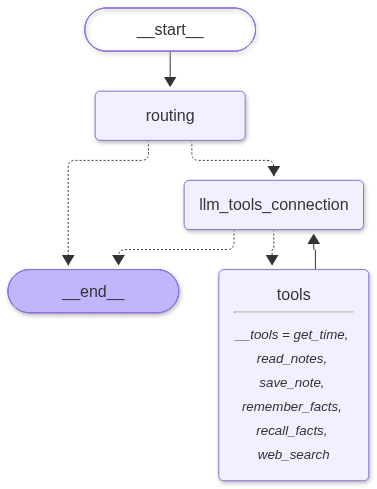

In [44]:
from langgraph.graph import StateGraph , START , END 
from langgraph.graph.message import add_messages 
from langchain_core.messages import AnyMessage 
from typing import TypedDict , Annotated 

# State define >>
class Roket_State(TypedDict):
    messages : Annotated[list[AnyMessage],add_messages]
    
# Save tools : >>
tools = [get_time , read_notes , save_note , remember_facts , recall_facts , web_search]

Tools_name = {t.name : t for t in tools }

# connected the tools with LLM >> Bind tools 
LLM_bind_tools = LLM.bind_tools(tools)

# LLM connection >> 
from langchain_core.messages import trim_messages

# System prompt : >>
SYSTEM_PROMPT = [SystemMessage(content="""
You are Mate, a concise personal assistant.

Memory rules:
1. When the user shares a lasting personal fact,
   use remember_facts to save it.
2. When the user asks about previously shared personal
   information, use recall_facts.
3. Never invent personal facts.
4. Use the retrieved information to answer.
5. Keep answers concise.
""")]

def llm_tools_connection(state: Roket_State):

    recent = trim_messages(
        state["messages"],
        strategy="last",
        token_counter=len,
        max_tokens=20,
        start_on="human",
        include_system=False
    )

    response = LLM_bind_tools.invoke(
        SYSTEM_PROMPT + recent
    )

    return {"messages": [response]}

# Route node  
def route_node(state : Roket_State):
    result = direct_router(state['messages'][-1].content)
    
    if result is None:
        return {}
    return {'messages':[AIMessage(content=str(result))]} 

# after routing 
def after_routing(state:Roket_State):
    if isinstance(state['messages'][-1],AIMessage):
        return END 
    return "llm_tools_connection"
    

from langgraph.prebuilt import ToolNode, tools_condition
builder = StateGraph(Roket_State)
# Memory adding 
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver
connection  = sqlite3.connect("Rocket_memory.db",check_same_thread=False)

# Register nodes
builder.add_node("llm_tools_connection", llm_tools_connection)
builder.add_node("tools", ToolNode(tools=tools))
builder.add_node("routing", route_node)

# Entry point
builder.add_edge(START, "routing")

# Route direct responses or LLM requests
builder.add_conditional_edges(
    "routing",
    after_routing,
    {
        "llm_tools_connection": "llm_tools_connection",
        END: END
    }
)

# IMPORTANT: Route LLM tool calls to ToolNode
builder.add_conditional_edges(
    "llm_tools_connection",
    tools_condition,
    {
        "tools": "tools",
        END: END
    }
)

# After tool execution, return to LLM
builder.add_edge("tools", "llm_tools_connection")

# Compile with memory
Rocket = builder.compile(checkpointer=SqliteSaver(connection))

Rocket

In [45]:
# Function for response : >>

def ask(text, thread_id="main"):
    config = {"configurable": {"thread_id": thread_id}}
    return Rocket.invoke({"messages": [("user", text)]}, config)["messages"][-1].content

print(ask("My name is Sam and I study BCA.", thread_id="a"))
print(ask("What do I study?", thread_id="r"))   

Got it—Sam, BCA student.
You study BCA.


In [46]:
print(ask("Search for the latest Python release and save it as a note.", thread_id="plan"))
print(ask("read notes"))

I've saved a note with the latest Python release: **Python 3.15.2**.
User name: Sam
User Sam likes tea.
User's name is Sam.
User's name is Sam and they study BCA.
User's name is Sam and they study BCA.
Latest Python release: Python 3.15.2 (expedited security release, second maintenance release of 3.15).



##### Ability to speak , hear and talk 

In [52]:
# Mouth 
import subprocess
def speak(speak:str)->str:
    subprocess.run(['say',speak])
    
# ears 
from groq import Groq
import sounddevice as sd , wave 

stt = Groq()
rate = 16000 

def listen(seconds = 5 , path = 'input.wav') ->str:
    print("Listening...")
    audio = sd.rec(int(seconds * rate), samplerate=rate, channels=1, dtype="int16")
    sd.wait()
    with wave.open(path, "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)
        w.setframerate(rate)
        w.writeframes(audio.tobytes())
    with open(path, "rb") as f:
        result = stt.audio.transcriptions.create(
            file=('input.wav', f.read()),
            model="whisper-large-v3-turbo",
            language="en",
        )
    return result.text


In [54]:
speak("Hello, I am Rocket.")
text = listen()
print("You said:", text)
reply = ask(text)
print("Rocket:", reply)
speak(reply)

Listening...
You said:  What is the current situation about AI news?
Rocket: **AI News Snapshot (early Nov 2026)**  

- **Google Gemini 4 Argon**: Google’s latest Gemini model (Argon) adds multimodal reasoning, stronger coding assistance, and lower‑latency inference for enterprise tools.  
- **Meta “Carbon” & “Genie 4”**: Meta released the Carbon series of efficient LLMs focused on sustainability, plus Genie 4, a conversational agent with improved long‑context handling.  
- **OpenAI updates**: OpenAI announced incremental improvements to GPT‑4.5, emphasizing safety‑steering and real‑time web browsing capabilities for select partners.  
- **Enterprise AI trends**: A surge in AI‑augmented workflow platforms—particularly in finance and healthcare—driven by tighter data‑privacy regulations and the rollout of “AI‑first” cloud services from AWS, Azure, and Google Cloud.  
- **Policy & regulation**: The EU’s AI Act entered its first enforcement phase, prompting many vendors to add transparenc